# Dynamic Trust Evaluation — interval-level simulation

This notebook evaluates each node against its **current attack state at every interval**.
It uses 20 paired reporting runs, with separate calibration seeds 900–904. All workloads,
telemetry and SLA outcome uniforms are shared across strategies within a run.
Results are synthetic simulation evidence, not measurements of a deployed cloud or Fabric network.
Run all cells in order; the full experiment and scheduler-only threshold sweeps can take time.
Previous outputs have been cleared because they belong to the superseded model.

**Kaggle:** upload this notebook, select a Python notebook session, then Run All.
The standard Kaggle image provides NumPy, pandas, SciPy, scikit-learn, statsmodels and matplotlib.
Outputs are written to `/kaggle/working/evaluation_outputs` when that is the working directory;
download that folder after the session finishes. No Desktop paths or local files are required.

In [1]:
import hashlib, json, time, tracemalloc, platform
from bisect import bisect_left, insort
from dataclasses import dataclass
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t, ttest_rel, wilcoxon
from statsmodels.stats.proportion import proportion_confint
from sklearn.metrics import (confusion_matrix, roc_curve, precision_recall_curve,
                             roc_auc_score, average_precision_score, auc)
from IPython.display import display

N_NODES, T_INTERVALS, N_RUNS = 500, 1000, 20
MALICIOUS_RATIO, HISTORY_WINDOW = 0.25, 10
VM_PER_INTERVAL, CPU_CAPACITY = 200, 100.0
WARMUP, PERIODIC_K = 50, 50
DELTA, MODELED_CONSENSUS_MS, MODELED_TPS = 0.02, 10.0, 5000.0
P_IDLE, P_MAX, RERUN_ENERGY_PER_CPU = 100.0, 250.0, 2.0
CALIBRATION_SEEDS = tuple(range(900, 905))
REPORT_SEEDS = tuple(range(20260, 20260 + N_RUNS))
THRESHOLDS = np.round(np.arange(0.50, 0.951, 0.05), 2)
SENSITIVITIES = (4.0, 4.5, 5.0)
BEHAVIORS = ('on_off', 'always', 'gradual', 'random', 'recovered', 'collusion', 'sybil')
STRATEGIES = ('gbf', 'static_trust', 'proposed', 'periodic_trust', 'no_smoothing')
SCENARIOS = {'normal': VM_PER_INTERVAL, 'capacity_stress': 4500}
OUTPUT_DIR = Path.cwd() / 'evaluation_outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.precision', 4)
print('Execution platform:', platform.platform(), platform.python_version())


Execution platform: Linux-6.18.55+-x86_64-with-glibc2.39 3.13.15


## AHP weights and their provenance

The pairwise judgments below are **author-defined illustrative ratios**, not expert elicitation.
Their exact consistency (CR approximately zero) is constructed by those ratios and is not
independent validation. No expert panel or geometric-mean aggregation is claimed.
The Abnormality component is the mean of the same three resource discrepancies, so it
**double-counts those signals**. Equal-weight and reproducibly random-weight ablations below
measure weight sensitivity; they do not make Abnormality an independent feature.

In [2]:
PARAM_NAMES = ['CPU', 'Memory', 'Network', 'Migration', 'SLA', 'Abnormality']
AHP_MATRIX = np.array([[1,2,2,2,1,2], [.5,1,1,1,.5,1], [.5,1,1,1,.5,1],
                       [.5,1,1,1,.5,1], [1,2,2,2,1,2], [.5,1,1,1,.5,1]])
def ahp_weights(matrix):
    w = (matrix / matrix.sum(axis=0)).mean(axis=1)
    lam = np.mean(matrix @ w / w)
    return w, max(0.0, (lam-len(w))/(len(w)-1)/1.24)
W, CR = ahp_weights(AHP_MATRIX)
assert CR < .10
print(f'Author-defined AHP consistency ratio: {CR:.6f}')
display(pd.DataFrame({'parameter': PARAM_NAMES, 'weight': W}))


Author-defined AHP consistency ratio: 0.000000


,parameter,weight
0,CPU,0.250
1,Memory,0.125
2,Network,0.125
3,Migration,0.125
4,SLA,0.250
5,Abnormality,0.125


## Nodes, behavior and noisy monitoring

Attackers are assigned seven behavior types in balanced rotation after shuffling IDs.
On-off offsets are staggered; gradual drift reaches full magnitude over 300 intervals;
random attacks occur with probability 0.35; recovered nodes attack during [150, 450].
Colluding nodes fabricate successful SLA/migration reports. Sybil groups (up to three IDs)
share one physical host, its actual load and its capacity, while each ID advertises a full host.
All honest phases include ordinary measurement noise and a 5% chance of N(0,8) benign spikes.

In [3]:
@dataclass
class CloudNode:
    id: int
    is_malicious: bool
    behavior: str = 'honest'
    offset: int = 0
    physical_host: int = 0
    drift: float = 0.0

def initialize_nodes(n_nodes, malicious_ratio, rng):
    bad = rng.permutation(n_nodes)[:round(n_nodes * malicious_ratio)]
    nodes = [CloudNode(i, False, physical_host=i) for i in range(n_nodes)]
    for j, nid in enumerate(bad):
        nodes[nid].is_malicious = True
        nodes[nid].behavior = BEHAVIORS[j % len(BEHAVIORS)]
        nodes[nid].offset = int(rng.integers(0, 50))
    sybils = [n for n in nodes if n.behavior == 'sybil']
    for j, node in enumerate(sybils):
        node.physical_host = sybils[(j//3)*3].id
    return nodes

def monitor_resources(nodes, t, rng, base, phase):
    n = len(nodes)
    hosts = np.array([x.physical_host for x in nodes])
    actual = np.clip(base + 12*np.sin(2*np.pi*t/T_INTERVALS + phase)[:,None]
                     + rng.normal(0,3,(n,3))
                     + (rng.random((n,1)) < .06)*rng.uniform(15,35,(n,1)), 1,100)
    actual = actual[hosts]
    attacking, magnitudes = [], []
    for node in nodes:
        b = node.behavior
        node.drift = min(1.0, max(0.0, (t-50)/300)) if b == 'gradual' else 0.0
        active = ((t+node.offset)%50 > 30 if b == 'on_off' else
                  t > 50 if b == 'gradual' else rng.random() < .35 if b == 'random' else
                  150 <= t <= 450 if b == 'recovered' else
                  b in ('always','collusion','sybil'))
        attacking.append(active)
        magnitudes.append(node.drift if b == 'gradual' else 1.0)
    attacking = np.asarray(attacking, dtype=bool)
    error = rng.normal(0,1.5,(n,3)) + (rng.random((n,1)) < .05)*rng.normal(0,8,(n,3))
    reported = np.clip(actual + error, 0,100)
    lie = rng.uniform([20,20,10],[45,45,30],(n,3))*np.array(magnitudes)[:,None]
    reported[attacking] = np.clip(actual[attacking]-lie[attacking],0,100)
    migration_ok = rng.random(n) > np.where(attacking,.35,.05)
    sla_ok = rng.random(n) > np.where(attacking,.40,.06)
    colluding = np.array([x.behavior == 'collusion' for x in nodes])
    migration_ok[colluding] = True
    sla_ok[colluding] = True
    return {x.id: dict(actual_cpu=float(actual[i,0]), actual_mem=float(actual[i,1]),
            actual_bw=float(actual[i,2]), reported_cpu=float(reported[i,0]),
            reported_mem=float(reported[i,1]), reported_bw=float(reported[i,2]),
            migration_ok=bool(migration_ok[i]), sla_ok=bool(sla_ok[i]),
            is_attacking=bool(attacking[i]), advertised_capacity=CPU_CAPACITY)
            for i,x in enumerate(nodes)}

def generate_vm_requests(t, rng, base_rate):
    rate = base_rate*(1.0-.5*np.cos(2*np.pi*t/T_INTERVALS))
    return np.clip(rng.lognormal(np.log(8),.6,max(1,rng.poisson(rate))),5,20)

def build_environment(seed, n_nodes=N_NODES, t_intervals=T_INTERVALS):
    rng = np.random.default_rng(seed)
    nodes = initialize_nodes(n_nodes,MALICIOUS_RATIO,rng)
    base = rng.beta(2,5,(n_nodes,3))*80+5
    phase = rng.uniform(0,2*np.pi,n_nodes)
    actual, reported, flags, migration, sla, raw_bytes = [],[],[],[],[],[]
    for t in range(t_intervals):
        r = monitor_resources(nodes,t,rng,base,phase)
        actual.append([[v['actual_cpu'],v['actual_mem'],v['actual_bw']] for v in r.values()])
        reported.append([[v['reported_cpu'],v['reported_mem'],v['reported_bw']] for v in r.values()])
        flags.append([v['is_attacking'] for v in r.values()])
        migration.append([v['migration_ok'] for v in r.values()])
        sla.append([v['sla_ok'] for v in r.values()])
        raw_bytes.append(len(json.dumps(r,sort_keys=True).encode('utf-8')))
    return dict(nodes=nodes, actual=np.array(actual), reported=np.array(reported),
                y=np.array(flags), migration=np.array(migration), sla=np.array(sla),
                raw_bytes=np.array(raw_bytes), seed=seed, T=t_intervals)


## Trust computation and attack/recovery timing

Rolling resource consistency uses sensitivity selected only on calibration seeds.
Asymmetric smoothing uses α=0.45 when raw trust falls and α=0.08 when it recovers.
TTD/TTR are tracked per attack/recovery episode and node. Already-flagged attack starts
and already-clear recoveries have latency zero and are labeled explicitly. Episodes without
a matching transition before the next state change/end are censored, with rates reported.

In [4]:
def rolling_mean(x, window=HISTORY_WINDOW, initial=0.0):
    padded = np.concatenate([np.full((window,)+x.shape[1:], initial), x],axis=0)
    cs = np.cumsum(padded,axis=0)
    return (cs[window:]-cs[:-window])/window

def analyze_behavior(environment, sensitivity):
    discrepancy = np.abs(environment['actual']-environment['reported'])/100
    d = rolling_mean(discrepancy)
    resource = np.clip(1-sensitivity*d,0,1)
    migration = rolling_mean(environment['migration'].astype(float),initial=1)
    sla = rolling_mean(environment['sla'].astype(float),initial=1)
    abnormality = np.clip(1-sensitivity*d.mean(axis=2),0,1)
    return np.concatenate([resource,migration[:,:,None],sla[:,:,None],abnormality[:,:,None]],axis=2)

def compute_trust_scores(features, weights=W, smoothing=True):
    raw = np.clip(features @ weights,0,1)
    if not smoothing:
        return raw
    trust, prev = np.empty_like(raw), np.ones(raw.shape[1])
    for t, row in enumerate(raw):
        a = np.where(row < prev,.45,.08)
        prev = (1-a)*prev+a*row
        trust[t] = prev
    return trust

def detection_counts(y, flags):
    tn, fp, fn, tp = confusion_matrix(y.ravel(), flags.ravel(), labels=[False,True]).ravel()
    div = lambda a,b: float(a/b) if b else np.nan
    return dict(tp=int(tp),fp=int(fp),fn=int(fn),tn=int(tn),
                precision=div(tp,tp+fp), recall=div(tp,tp+fn),
                f1=div(2*tp,2*tp+fp+fn), fpr=div(fp,fp+tn), fnr=div(fn,fn+tp))

def episode_latencies(y, flags, nodes):
    records=[]
    for nid,node in enumerate(nodes):
        state=y[:,nid]
        starts=np.flatnonzero(state & ~np.r_[False,state[:-1]])
        recoveries=np.flatnonzero(~state & np.r_[False,state[:-1]])
        for kind,edges,target in [('TTD',starts,True),('TTR',recoveries,False)]:
            for start in edges:
                changes=np.flatnonzero(state[start:] != state[start])
                end=start+changes[0] if len(changes) else len(state)
                matches=np.flatnonzero(flags[start:end,nid] == target)
                latency=int(matches[0]) if len(matches) else np.nan
                records.append(dict(node=nid,behavior=node.behavior,kind=kind,start=int(start),
                    latency=latency,censored=not len(matches),already_in_target=bool(flags[start,nid]==target)))
    return pd.DataFrame(records)

def calibrate(seeds=CALIBRATION_SEEDS, n_nodes=N_NODES, t_intervals=T_INTERVALS):
    rows=[]
    for seed in seeds:
        env=build_environment(seed,n_nodes,t_intervals)
        for sensitivity in SENSITIVITIES:
            trust=compute_trust_scores(analyze_behavior(env,sensitivity))
            for threshold in THRESHOLDS:
                rows.append(dict(seed=seed,sensitivity=sensitivity,threshold=threshold,
                                 **detection_counts(env['y'],trust<threshold)))
    table=pd.DataFrame(rows)
    # Predeclared objective: maximum mean interval F1; ties prefer lower FPR, then lower threshold.
    ranking=table.groupby(['sensitivity','threshold'],as_index=False)[['f1','fpr']].mean()
    best=ranking.sort_values(['f1','fpr','threshold'],ascending=[False,True,True]).iloc[0]
    return float(best.sensitivity),float(best.threshold),table


## Simulated hash-chained ledger

This is a single-process simulated ledger. It implements no distributed consensus, peers,
orderer, Fabric endorsement policy or network security. Consensus latency (10 ms/block)
and throughput capacity (5000 records/s) are explicit **modeled inputs**, not benchmarks.
Storage comparisons use (1) full-score logging with identical block format and transition
events, (2) delta/transition score logging, and (3) raw telemetry JSON as a separate reference.
Bytes include serialized block metadata and hash; genesis is included in total ledger bytes.
Delta compares to the last committed (unrounded) score, so small changes accumulate.

In [5]:
class Block:
    def __init__(self,index,timestamp,records,events,previous_hash):
        self.index,self.timestamp=index,timestamp
        self.records,self.events,self.previous_hash=records,events,previous_hash
        self.hash=self.compute_hash()
    def payload(self):
        return dict(index=self.index,timestamp=self.timestamp,records=self.records,
                    events=self.events,previous_hash=self.previous_hash)
    def compute_hash(self):
        return hashlib.sha256(json.dumps(self.payload(),sort_keys=True).encode()).hexdigest()
    def size_bytes(self):
        return len(json.dumps(dict(**self.payload(),hash=self.hash),sort_keys=True).encode('utf-8'))

class TrustBlockchain:
    def __init__(self,delta=DELTA,full=False):
        self.chain=[Block(0,-1,{},[],'0'*64)]
        self.previous={}
        self.flags={}
        self.delta,self.full=delta,full
    def add_block(self,t,scores,threshold):
        recs,events={},[]
        for nid,s in enumerate(scores):
            flagged=bool(s<threshold)
            transition=nid in self.flags and flagged != self.flags[nid]
            if self.full or nid not in self.previous or abs(s-self.previous[nid])>=self.delta or transition:
                recs[str(nid)]=round(float(s),3)
                self.previous[nid]=float(s)
            if transition or (nid not in self.flags and flagged):
                events.append(dict(node=nid,event='flag' if flagged else 'clear'))
            self.flags[nid]=flagged
        if not recs and not events:
            return None
        block=Block(len(self.chain),int(t),recs,events,self.chain[-1].hash)
        self.chain.append(block)
        return block
    def is_valid(self):
        return (self.chain[0].previous_hash=='0'*64 and
                all(b.hash==b.compute_hash() for b in self.chain) and
                all(b.previous_hash==a.hash for a,b in zip(self.chain,self.chain[1:])))

def ledger_comparison(trust,threshold,raw_bytes,delta=DELTA):
    rows=[]
    ledgers={}
    for name,full in [('delta_scores',False),('full_scores',True)]:
        ledger=TrustBlockchain(delta,full)
        sizes=[]
        records=0
        for t,row in enumerate(trust):
            block=ledger.add_block(t,row,threshold)
            sizes.append(block.size_bytes() if block else 0)
            records+=len(block.records) if block else 0
        assert ledger.is_valid()
        rows.append(dict(design=name,bytes_per_interval=np.mean(sizes),
            total_bytes=sum(b.size_bytes() for b in ledger.chain),blocks=len(ledger.chain)-1,
            modeled_consensus_ms=(len(ledger.chain)-1)*MODELED_CONSENSUS_MS,
            modeled_record_service_seconds=records/MODELED_TPS))
        ledgers[name]=ledger
    rows.append(dict(design='raw_telemetry_json',bytes_per_interval=np.mean(raw_bytes),
                     total_bytes=int(sum(raw_bytes)),blocks=np.nan,
                     modeled_consensus_ms=np.nan,modeled_record_service_seconds=np.nan))
    return rows,ledgers['delta_scores']


## Scheduling, physical capacity, energy and overhead

Best-fit selects the feasible ID leaving the least advertised capacity. Static trust uses
dynamic scores through interval 50 and then freezes; periodic trust refreshes every 50 intervals.
GBF performs no trust computation. Sybil ID capacity is separately advertised, but placement
and energy share its physical host. Overbooking causes SLA failure. Other failure probabilities
are 35% while attacking and 3% while honest. Outcomes use common per-request uniforms.
Requests last one interval; throughput counts successful completions, with assigned, dropped
and failed requests also reported. Actual load plus assigned work drives a convex power curve;
failed work adds a modeled rerun energy penalty, without counting a completion on this interval.
Intervals represent one time unit, so energy is in model units, not measured joules.
Latency excludes environment generation and offline evaluation; tracemalloc measures peak
Python allocations for trust computation and scheduler replay (maximum of the two peaks,
not total process RAM). CPU time uses process_time. Periodic trust continuously computes
trust but publishes a new scheduling view only every K intervals.

In [6]:
def greedy_best_fit_allocate(free,requests,trust=None,threshold=0):
    allowed=np.ones(len(free),bool) if trust is None else trust>=threshold
    # Sorted free-capacity index implements exactly the same best-fit rule without
    # scanning every node for each request. Ties use the smallest node ID.
    available=sorted((float(free[nid]),nid) for nid in range(len(free)) if allowed[nid])
    allocations=[]
    for demand in requests:
        position=bisect_left(available,(float(demand),-1))
        if position==len(available):
            allocations.append(None)
        else:
            capacity,nid=available.pop(position)
            insort(available,(capacity-float(demand),nid))
            allocations.append(nid)
    return allocations

def power_model(utilization):
    return P_IDLE+(P_MAX-P_IDLE)*np.clip(utilization,0,1)**2

def run_simulation(strategy,environment,outcome_seed,trust,threshold,base_rate,
                   trust_seconds=0.0,trace_memory=True,trust_cpu_seconds=0.0,trust_peak_bytes=0):
    n,T=len(environment['nodes']),environment['T']
    hosts=np.array([x.physical_host for x in environment['nodes']])
    physical=np.unique(hosts)
    rng_requests=np.random.default_rng(environment['seed']+100000)
    rng_outcomes=np.random.default_rng(outcome_seed)
    log=[]
    start_cpu=time.process_time()
    if trace_memory:
        tracemalloc.start()
    for t in range(T):
        if strategy=='gbf': active=None
        elif strategy=='static_trust': active=trust[min(t,WARMUP)]
        elif strategy=='periodic_trust': active=trust[(t//PERIODIC_K)*PERIODIC_K]
        else: active=trust[t]
        requests=generate_vm_requests(t,rng_requests,base_rate)
        uniforms=rng_outcomes.random(len(requests))
        free=CPU_CAPACITY-environment['reported'][t,:,0]
        tick=time.perf_counter()
        allocations=greedy_best_fit_allocate(free,requests,active,threshold)
        schedule_time=time.perf_counter()-tick
        actual_load=environment['actual'][t,:,0].copy()
        assigned=failed=0
        rerun=0.0
        for j,nid in enumerate(allocations):
            if nid is None: continue
            assigned+=1
            host=hosts[nid]
            actual_load[host]+=requests[j]
            violation=(actual_load[host]>CPU_CAPACITY or
                       uniforms[j] < (.35 if environment['y'][t,nid] else .03))
            failed+=int(violation)
            if violation: rerun+=requests[j]*RERUN_ENERGY_PER_CPU
        log.append(dict(t=t,strategy=strategy,n_requests=len(requests),assigned=assigned,
            throughput=assigned-failed,dropped_vms=len(requests)-assigned,sla_violations=failed,
            resource_utilization=np.clip(actual_load[physical]/CPU_CAPACITY,0,1).mean(),
            energy=power_model(actual_load[physical]/CPU_CAPACITY).sum()+rerun,
            scheduling_time=schedule_time,decision_latency_ms=1000*schedule_time/len(requests)))
    cpu_seconds=time.process_time()-start_cpu
    peak=tracemalloc.get_traced_memory()[1] if trace_memory else np.nan
    if trace_memory: tracemalloc.stop()
    df=pd.DataFrame(log)
    counts=detection_counts(environment['y'], np.zeros_like(environment['y']) if strategy=='gbf'
                            else np.array([trust[min(t,WARMUP)] if strategy=='static_trust' else
                             trust[(t//PERIODIC_K)*PERIODIC_K] if strategy=='periodic_trust' else trust[t]
                             for t in range(T)])<threshold)
    totals={k:float(df[k].mean()) for k in ['throughput','dropped_vms','sla_violations','energy','resource_utilization']}
    totals.update(counts)
    totals.update(strategy=strategy,decision_latency_ms=1000*df.scheduling_time.sum()/df.n_requests.sum(),
       dts_time_per_node_us=1e6*trust_seconds/(T*n) if strategy!='gbf' else 0.0,
       cpu_seconds=cpu_seconds+(trust_cpu_seconds if strategy!='gbf' else 0),
       peak_python_bytes=max(peak,trust_peak_bytes) if trace_memory else np.nan)
    return df,totals

def measure_trust(environment, smoothing=True):
    tracemalloc.start()
    wall,cpu=time.perf_counter(),time.process_time()
    features=analyze_behavior(environment,SENSITIVITY)
    scores=compute_trust_scores(features,smoothing=smoothing)
    seconds,cpu_seconds=time.perf_counter()-wall,time.process_time()-cpu
    peak=tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return features,scores,seconds,cpu_seconds,peak


## Calibrate once, report on disjoint seeds

The predeclared calibration objective maximizes mean per-run interval F1 (tie: lower FPR).
All weight and smoothing ablations retain this chosen threshold/sensitivity; they are not
retuned on reporting data. Threshold sweeps are descriptive, not a second selection step.
Trust arrays are saved once per run; threshold sweeps only replay the scheduler.

In [7]:
SENSITIVITY, TRUST_THRESHOLD, calibration = calibrate()
assert set(CALIBRATION_SEEDS).isdisjoint(REPORT_SEEDS)
print(f'Calibration seeds {CALIBRATION_SEEDS}: sensitivity={SENSITIVITY}, tau={TRUST_THRESHOLD}')
calibration.to_csv(OUTPUT_DIR/'calibration.csv',index=False)


Calibration seeds (900, 901, 902, 903, 904): sensitivity=5.0, tau=0.7


In [8]:
run_records, detection_records, behavior_records, latency_records = [],[],[],[]
storage_records, ablation_records, curve_records, sweep_records = [],[],[],[]
random_weights=np.random.default_rng(4242).dirichlet(np.ones(6))
blockchain_ref=None
for run,seed in enumerate(REPORT_SEEDS):
    environment=build_environment(seed)
    features,trust,trust_seconds,trust_cpu,trust_peak=measure_trust(environment)
    _,raw_trust,raw_seconds,raw_cpu,raw_peak=measure_trust(environment,smoothing=False)
    # Static trust stops monitoring/computing trust after the warm-up snapshot.
    warm_environment=dict(environment)
    for key in ['actual','reported','migration','sla']:
        warm_environment[key]=environment[key][:WARMUP+1]
    _,_,static_seconds,static_cpu,static_peak=measure_trust(warm_environment)
    np.savez_compressed(OUTPUT_DIR/f'trust_run_{run:02d}.npz',trust=trust,y=environment['y'])
    detection_records.append(dict(run=run,**detection_counts(environment['y'],trust<TRUST_THRESHOLD)))
    honest=np.array([not node.is_malicious for node in environment['nodes']])
    honest_counts=detection_counts(environment['y'][:,honest],trust[:,honest]<TRUST_THRESHOLD)
    detection_records[-1].update(honest_fp=honest_counts['fp'],honest_tn=honest_counts['tn'],
                                honest_fpr=honest_counts['fpr'])
    lo,hi=proportion_confint(honest_counts['fp'],honest_counts['fp']+honest_counts['tn'],method='beta')
    detection_records[-1].update(honest_cp95_low=lo,honest_cp95_high=hi)
    for behavior in BEHAVIORS:
        mask=np.array([node.behavior==behavior for node in environment['nodes']])
        behavior_records.append(dict(run=run,behavior=behavior,
            **detection_counts(environment['y'][:,mask],trust[:,mask]<TRUST_THRESHOLD)))
    latency=episode_latencies(environment['y'],trust<TRUST_THRESHOLD,environment['nodes'])
    latency['run']=run; latency_records.append(latency)
    storage,blockchain_ref=ledger_comparison(trust,TRUST_THRESHOLD,environment['raw_bytes'])
    storage_records.extend(dict(run=run,**row) for row in storage)
    for name,weights in [('ahp',W),('equal',np.ones(6)/6),('random',random_weights)]:
        scores=compute_trust_scores(features,weights)
        ablation_records.append(dict(run=run,ablation=name,
            **detection_counts(environment['y'],scores<TRUST_THRESHOLD)))
    ablation_records.append(dict(run=run,ablation='no_smoothing',
        **detection_counts(environment['y'],raw_trust<TRUST_THRESHOLD)))
    for scenario,rate in SCENARIOS.items():
        for strategy in STRATEGIES:
            seconds,cpu,peak=(0,0,0) if strategy=='gbf' else (
                (static_seconds,static_cpu,static_peak) if strategy=='static_trust' else
                (raw_seconds,raw_cpu,raw_peak) if strategy=='no_smoothing' else
                (trust_seconds,trust_cpu,trust_peak))
            _,record=run_simulation(strategy,environment,77000+run,
                raw_trust if strategy=='no_smoothing' else trust,TRUST_THRESHOLD,rate,
                seconds,trust_cpu_seconds=cpu,trust_peak_bytes=peak)
            run_records.append(dict(run=run,scenario=scenario,**record))
    # Curves use negative DTS: larger values indicate stronger evidence of attack.
    y,score=environment['y'].ravel(),-trust.ravel()
    fpr,tpr,_=roc_curve(y,score)
    precision,recall,_=precision_recall_curve(y,score)
    curve_records.append(dict(run=run,roc_auc=roc_auc_score(y,score),
        pr_auc=auc(recall,precision),average_precision=average_precision_score(y,score)))
    if run==0:
        curve_plot=(fpr,tpr,precision,recall)
    for threshold in THRESHOLDS:
        metrics=detection_counts(environment['y'],trust<threshold)
        for scenario,rate in SCENARIOS.items():
            _,scheduled=run_simulation('proposed',environment,77000+run,trust,threshold,rate,
                                       trace_memory=False)
            sweep_records.append(dict(run=run,scenario=scenario,threshold=threshold,
                **metrics,throughput=scheduled['throughput'],dropped_vms=scheduled['dropped_vms'],
                sla_violations=scheduled['sla_violations']))
    print(f'Completed paired reporting run {run+1}/{N_RUNS}',flush=True)
results=pd.DataFrame(run_records)
detection=pd.DataFrame(detection_records)
behavior_results=pd.DataFrame(behavior_records)
latencies=pd.concat(latency_records,ignore_index=True)
storage_results=pd.DataFrame(storage_records)
ablations=pd.DataFrame(ablation_records)
curves=pd.DataFrame(curve_records)
threshold_sweep=pd.DataFrame(sweep_records)


Completed paired reporting run 1/20
Completed paired reporting run 2/20
Completed paired reporting run 3/20
Completed paired reporting run 4/20
Completed paired reporting run 5/20
Completed paired reporting run 6/20
Completed paired reporting run 7/20
Completed paired reporting run 8/20
Completed paired reporting run 9/20
Completed paired reporting run 10/20
Completed paired reporting run 11/20
Completed paired reporting run 12/20
Completed paired reporting run 13/20
Completed paired reporting run 14/20
Completed paired reporting run 15/20
Completed paired reporting run 16/20
Completed paired reporting run 17/20
Completed paired reporting run 18/20
Completed paired reporting run 19/20
Completed paired reporting run 20/20


## Per-run statistics and paired comparisons

Mean, sample SD and two-sided 95% Student-t intervals use the **run** as the independent
replication unit. Paired t-tests and Wilcoxon tests compare proposed with both GBF and static
trust on matched seeds for each scenario. P-values are exploratory and unadjusted across
metrics. NaN indicates an undefined metric (for example precision when nothing is flagged).
The Clopper–Pearson interval treats honest-node intervals as Bernoulli trials; temporal
dependence can make it optimistic, so the separate across-run CI is also reported.

In [9]:
def mean_ci(values):
    x=np.asarray(values,dtype=float); x=x[np.isfinite(x)]
    n=len(x); mean=float(np.mean(x)) if n else np.nan
    sd=float(np.std(x,ddof=1)) if n>1 else np.nan
    margin=student_t.ppf(.975,n-1)*sd/np.sqrt(n) if n>1 else np.nan
    return dict(n=n,mean=mean,sd=sd,ci95_low=mean-margin,ci95_high=mean+margin)

def summarize(frame,groups,metrics):
    rows=[]
    for keys,group in frame.groupby(groups):
        if not isinstance(keys,tuple): keys=(keys,)
        for metric in metrics:
            rows.append(dict(zip(groups,keys),metric=metric,**mean_ci(group[metric])))
    return pd.DataFrame(rows)

metrics=['throughput','dropped_vms','sla_violations','resource_utilization','energy',
         'decision_latency_ms','dts_time_per_node_us','cpu_seconds','peak_python_bytes']
summary=summarize(results,['scenario','strategy'],metrics)
detection_summary=pd.DataFrame([dict(metric=k,**mean_ci(detection[k]))
                               for k in ['precision','recall','f1','fpr','fnr','honest_fpr']])
display(summary)
display(detection_summary)
counts=detection[['tp','fp','fn','tn']].sum().astype(int)
confusion=pd.DataFrame([[counts.tn,counts.fp],[counts.fn,counts.tp]],
    index=['Actual inactive','Actual attacking'],columns=['Predicted clear','Predicted flagged'])
print(f'Confusion matrix: {N_RUNS} runs x {T_INTERVALS} intervals x {N_NODES} nodes '
      f'= {N_RUNS*T_INTERVALS*N_NODES:,} node-intervals')
display(confusion)
honest_fp=int(detection.honest_fp.sum())
honest_total=int((detection.honest_fp+detection.honest_tn).sum())
cp=proportion_confint(honest_fp,honest_total,alpha=.05,method='beta')
honest_fpr_report=pd.DataFrame([dict(denominator='honest nodes only',fp=honest_fp,
    node_intervals=honest_total,pooled_fpr=honest_fp/honest_total,
    cp95_low=cp[0],cp95_high=cp[1],**mean_ci(detection.honest_fpr))])
display(honest_fpr_report)
behavior_summary=summarize(behavior_results,['behavior'],['recall'])
latency_runs=latencies.groupby(['run','behavior','kind'],as_index=False).agg(
    latency=('latency','mean'),censored_rate=('censored','mean'),
    already_in_target_rate=('already_in_target','mean'))
latency_summary=summarize(latency_runs,['behavior','kind'],
                         ['latency','censored_rate','already_in_target_rate'])
storage_summary=summarize(storage_results,['design'],['bytes_per_interval','total_bytes'])
ablation_summary=summarize(ablations,['ablation'],['precision','recall','f1','fpr'])
display(behavior_summary); display(latency_summary); display(storage_summary); display(ablation_summary)
tests=[]
for scenario in SCENARIOS:
    part=results[results.scenario==scenario]
    for baseline in ['gbf','static_trust']:
        for metric in metrics:
            paired=part[part.strategy.isin(['proposed',baseline])].pivot(index='run',columns='strategy',values=metric).dropna()
            a,b=paired.proposed.to_numpy(),paired[baseline].to_numpy()
            if np.all(a==b): tp,wp=1.0,1.0
            else: tp=float(ttest_rel(a,b).pvalue); wp=float(wilcoxon(a,b).pvalue)
            tests.append(dict(scenario=scenario,baseline=baseline,metric=metric,n=len(a),
                mean_paired_difference=np.mean(a-b),ttest_rel_p=tp,wilcoxon_p=wp))
paired_tests=pd.DataFrame(tests)
display(paired_tests)
display(pd.DataFrame([dict(metric=k,**mean_ci(curves[k])) for k in ['roc_auc','pr_auc','average_precision']]))


,scenario,strategy,metric,n,mean,sd,ci95_low,ci95_high
0,capacity_stress,gbf,throughput,20,2.8856e+03,21.9870,2.8753e+03,2.8958e+03
1,capacity_stress,gbf,dropped_vms,20,1.0746e+03,20.7791,1.0649e+03,1.0843e+03
2,capacity_stress,gbf,sla_violations,20,5.4018e+02,3.7939,5.3841e+02,5.4196e+02
3,capacity_stress,gbf,resource_utilization,20,9.1364e-01,0.0029,9.1229e-01,9.1499e-01
4,capacity_stress,gbf,energy,20,1.2375e+05,222.6543,1.2365e+05,1.2386e+05
...,...,...,...,...,...,...,...,...
85,normal,static_trust,energy,20,6.1886e+04,365.2954,6.1715e+04,6.2057e+04
86,normal,static_trust,decision_latency_ms,20,1.1412e-02,0.0002,1.1342e-02,1.1482e-02
87,normal,static_trust,dts_time_per_node_us,20,1.1745e-02,0.0002,1.1658e-02,1.1833e-02
88,normal,static_trust,cpu_seconds,20,8.0828e+00,0.1661,8.0051e+00,8.1606e+00


,metric,n,mean,sd,ci95_low,ci95_high
0,precision,20,0.8498,0.0038,0.8480,0.8516
1,recall,20,0.9443,0.0056,0.9417,0.9469
2,f1,20,0.8945,0.0033,0.8930,0.8961
3,fpr,20,0.0360,0.0011,0.0355,0.0365
4,fnr,20,0.0557,0.0056,0.0531,0.0583
5,honest_fpr,20,0.0000,0.0000,0.0000,0.0000


Confusion matrix: 20 runs x 1000 intervals x 500 nodes = 10,000,000 node-intervals


,Predicted clear,Predicted flagged
Actual inactive,7931112,295986
Actual attacking,98762,1674140


,denominator,fp,node_intervals,pooled_fpr,cp95_low,cp95_high,n,mean,sd,ci95_low,ci95_high
0,honest nodes only,0,7500000,0.0,0.0,4.9185e-07,20,0.0,0.0,0.0,0.0


...

,behavior,kind,metric,n,mean,sd,ci95_low,ci95_high
0,always,TTD,latency,20,4.6389,0.3860,4.4583,4.8195
1,always,TTD,censored_rate,20,0.0000,0.0000,0.0000,0.0000
2,always,TTD,already_in_target_rate,20,0.0000,0.0000,0.0000,0.0000
3,collusion,TTD,latency,20,8.0889,8.0613,4.3161,11.8617
4,collusion,TTD,censored_rate,20,0.0000,0.0000,0.0000,0.0000
5,collusion,TTD,already_in_target_rate,20,0.0000,0.0000,0.0000,0.0000
6,gradual,TTD,latency,20,51.7472,2.9823,50.3515,53.1430
7,gradual,TTD,censored_rate,20,0.0000,0.0000,0.0000,0.0000
8,gradual,TTD,already_in_target_rate,20,0.0000,0.0000,0.0000,0.0000
9,on_off,TTD,latency,20,3.9437,0.2033,3.8486,4.0389


,design,metric,n,mean,sd,ci95_low,ci95_high
0,delta_scores,bytes_per_interval,20,9.2265e+02,5.9427,9.1987e+02,9.2543e+02
1,delta_scores,total_bytes,20,9.2287e+05,5942.7010,9.2009e+05,9.2565e+05
2,full_scores,bytes_per_interval,20,7.0986e+03,1.3946,7.0979e+03,7.0992e+03
3,full_scores,total_bytes,20,7.0988e+06,1394.5625,7.0982e+06,7.0995e+06
4,raw_telemetry_json,bytes_per_interval,20,1.4953e+05,111.7453,1.4948e+05,1.4959e+05
5,raw_telemetry_json,total_bytes,20,1.4953e+08,111745.3242,1.4948e+08,1.4959e+08


,ablation,metric,n,mean,sd,ci95_low,ci95_high
0,ahp,precision,20,0.8498,0.0038,0.8480,0.8516
1,ahp,recall,20,0.9443,0.0056,0.9417,0.9469
2,ahp,f1,20,0.8945,0.0033,0.8930,0.8961
3,ahp,fpr,20,0.0360,0.0011,0.0355,0.0365
4,equal,precision,20,0.8477,0.0034,0.8461,0.8493
5,equal,recall,20,0.9466,0.0055,0.9440,0.9492
6,equal,f1,20,0.8944,0.0028,0.8931,0.8957
7,equal,fpr,20,0.0367,0.0010,0.0362,0.0371
8,no_smoothing,precision,20,0.9141,0.0033,0.9125,0.9157
9,no_smoothing,recall,20,0.9384,0.0071,0.9351,0.9417


,scenario,baseline,metric,n,mean_paired_difference,ttest_rel_p,wilcoxon_p
0,normal,gbf,throughput,20,1.6360e+00,4.1731e-09,1.9073e-06
1,normal,gbf,dropped_vms,20,0.0000e+00,1.0000e+00,1.0000e+00
2,normal,gbf,sla_violations,20,-1.6360e+00,4.1731e-09,1.9073e-06
3,normal,gbf,resource_utilization,20,2.2940e-04,1.2717e-08,1.9073e-06
4,normal,gbf,energy,20,-1.9908e+01,9.6165e-13,1.9073e-06
5,normal,gbf,decision_latency_ms,20,-1.3409e-03,1.5210e-21,1.9073e-06
6,normal,gbf,dts_time_per_node_us,20,2.2688e-01,2.2822e-23,1.9073e-06
7,normal,gbf,cpu_seconds,20,-1.9102e-01,2.3395e-06,1.3351e-05
8,normal,gbf,peak_python_bytes,20,7.1348e+07,1.0090e-99,1.9073e-06
9,normal,static_trust,throughput,20,4.6715e-01,1.5410e-07,1.9073e-06


,metric,n,mean,sd,ci95_low,ci95_high
0,roc_auc,20,0.9896,0.0005,0.9894,0.9899
1,pr_auc,20,0.9488,0.0034,0.9472,0.9504
2,average_precision,20,0.9488,0.0034,0.9472,0.9504


## Storage sensitivity and figures

The storage grid varies δ and N using independently generated environments and 20 runs per
cell. This includes Sybil physical-host grouping at each N. It measures storage only and
does not rerun scheduling. Raw telemetry and full-score logging retain the same definitions.

Storage grid complete for N=100
Storage grid complete for N=250
Storage grid complete for N=500


,N,delta,design,metric,n,mean,sd,ci95_low,ci95_high
0,100,0.0,delta_scores,bytes_per_interval,20,1.5079e+03,0.6302,1.5076e+03,1.5082e+03
1,100,0.0,delta_scores,total_bytes,20,1.5081e+06,630.1535,1.5079e+06,1.5084e+06
2,100,0.0,full_scores,bytes_per_interval,20,1.5079e+03,0.6302,1.5076e+03,1.5082e+03
3,100,0.0,full_scores,total_bytes,20,1.5081e+06,630.1535,1.5079e+06,1.5084e+06
4,100,0.0,raw_telemetry_json,bytes_per_interval,20,2.9819e+04,30.3922,2.9805e+04,2.9834e+04
...,...,...,...,...,...,...,...,...,...
85,500,0.1,delta_scores,total_bytes,20,3.4830e+05,2728.5930,3.4702e+05,3.4958e+05
86,500,0.1,full_scores,bytes_per_interval,20,7.0986e+03,1.3946,7.0979e+03,7.0992e+03
87,500,0.1,full_scores,total_bytes,20,7.0988e+06,1394.5625,7.0982e+06,7.0995e+06
88,500,0.1,raw_telemetry_json,bytes_per_interval,20,1.4953e+05,111.7453,1.4948e+05,1.4959e+05


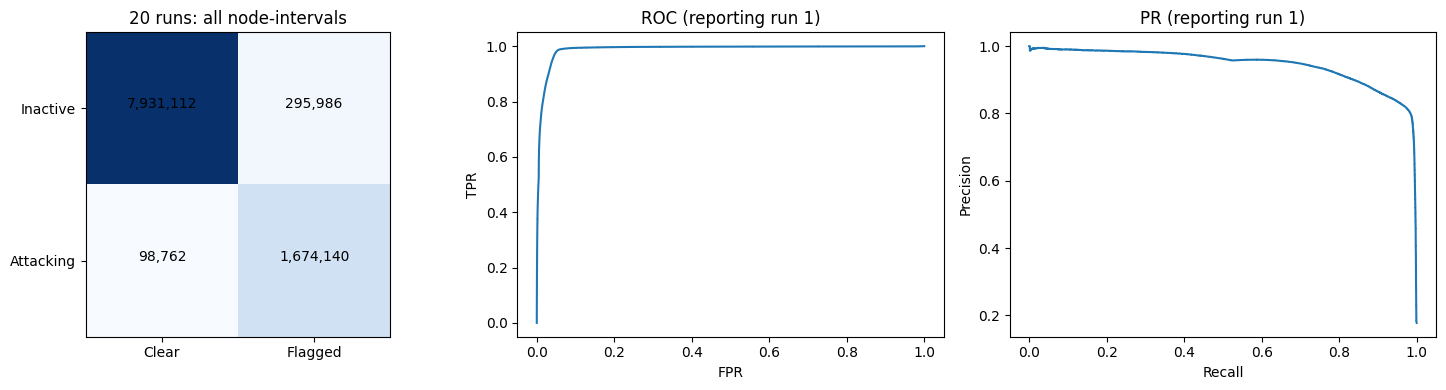

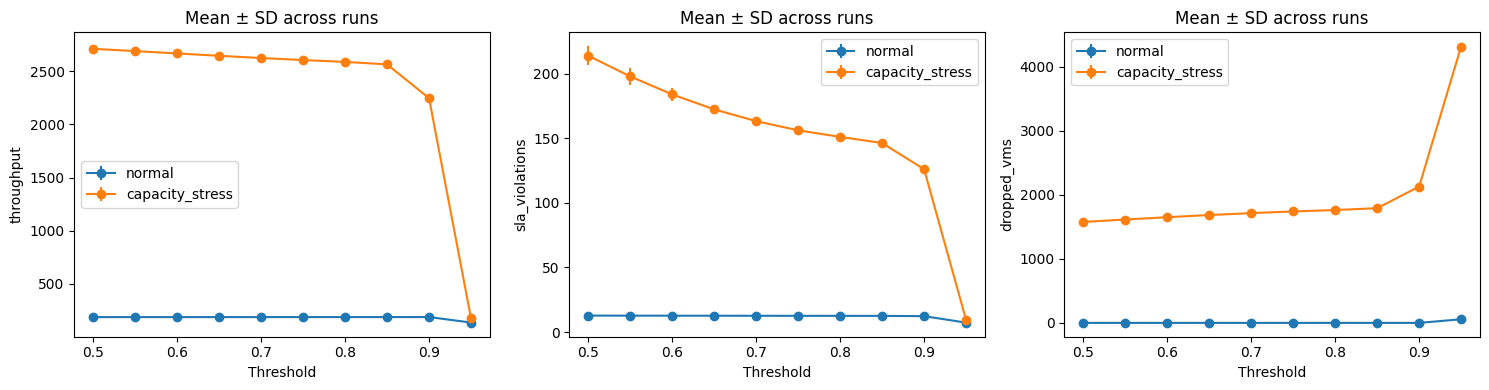

Last simulated ledger valid: True


In [10]:
storage_grid_rows=[]
for n_nodes in (100,250,500):
    for run,seed in enumerate(REPORT_SEEDS):
        if n_nodes==N_NODES:
            saved=np.load(OUTPUT_DIR/f'trust_run_{run:02d}.npz')
            scores=saved['trust']
            # Reuse measured raw telemetry totals from the main run.
            raw=np.full(T_INTERVALS,storage_results.query("run == @run and design == 'raw_telemetry_json'").bytes_per_interval.iloc[0])
        else:
            env=build_environment(seed,n_nodes)
            scores=compute_trust_scores(analyze_behavior(env,SENSITIVITY))
            raw=env['raw_bytes']
        for delta in (0.0,.01,.02,.05,.10):
            rows,_=ledger_comparison(scores,TRUST_THRESHOLD,raw,delta)
            storage_grid_rows.extend(dict(run=run,N=n_nodes,delta=delta,**r) for r in rows)
    print(f'Storage grid complete for N={n_nodes}',flush=True)
storage_grid=pd.DataFrame(storage_grid_rows)
storage_grid_summary=summarize(storage_grid,['N','delta','design'],['bytes_per_interval','total_bytes'])
display(storage_grid_summary)

fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].imshow(confusion,cmap='Blues')
for i in range(2):
    for j in range(2): axes[0].text(j,i,f'{confusion.iloc[i,j]:,}',ha='center')
axes[0].set(xticks=[0,1],xticklabels=['Clear','Flagged'],yticks=[0,1],
    yticklabels=['Inactive','Attacking'],title=f'{N_RUNS} runs: all node-intervals')
fpr,tpr,precision,recall=curve_plot
axes[1].plot(fpr,tpr); axes[1].set(xlabel='FPR',ylabel='TPR',title='ROC (reporting run 1)')
axes[2].plot(recall,precision); axes[2].set(xlabel='Recall',ylabel='Precision',title='PR (reporting run 1)')
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'detection_curves.png'); plt.show()

fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axes,['throughput','sla_violations','dropped_vms']):
    for scenario in SCENARIOS:
        s=threshold_sweep[threshold_sweep.scenario==scenario].groupby('threshold')[metric].agg(['mean','std'])
        ax.errorbar(s.index,s['mean'],yerr=s['std'],label=scenario,marker='o')
    ax.set(xlabel='Threshold',ylabel=metric,title='Mean ± SD across runs'); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'threshold_sweep.png'); plt.show()
print('Last simulated ledger valid:',blockchain_ref.is_valid())


In [11]:
exports=dict(per_run_results=results,comparative_summary=summary,detection_per_run=detection,
    detection_summary=detection_summary,detection_confusion_matrix=confusion,
    honest_fpr=honest_fpr_report,behavior_recall=behavior_summary,episode_latencies=latencies,
    latency_summary=latency_summary,ledger_per_run=storage_results,ledger_summary=storage_summary,
    paired_tests=paired_tests,weight_ablations=ablations,ablation_summary=ablation_summary,
    curve_metrics=curves,threshold_sweep=threshold_sweep,storage_grid=storage_grid,
    storage_grid_summary=storage_grid_summary)
for name,frame in exports.items():
    frame.to_csv(OUTPUT_DIR/f'{name}.csv',index=(name=='detection_confusion_matrix'))
metadata=dict(n_runs=N_RUNS,n_nodes=N_NODES,t_intervals=T_INTERVALS,
    calibration_seeds=CALIBRATION_SEEDS,report_seeds=REPORT_SEEDS,
    sensitivity=SENSITIVITY,threshold=TRUST_THRESHOLD,random_weights=random_weights.tolist(),
    ahp_provenance='author-defined illustrative ratios; not expert elicitation',
    ledger='single-process simulated hash chain',modeled_consensus_ms=MODELED_CONSENSUS_MS,
    modeled_tps=MODELED_TPS,energy_units='model units per one-unit interval',
    memory_measure='maximum tracemalloc peak of trust computation and scheduler replay')
(OUTPUT_DIR/'experiment_metadata.json').write_text(json.dumps(metadata,indent=2))
print('Exports:',OUTPUT_DIR.resolve())


Exports: /kaggle/working/evaluation_outputs
